# Multidisciplinary Analysis (MDA): Gauss-Seidel, Jacobi and Newton

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L11/L11_multidisciplinary_analysis.ipynb)
### MECH 559 - Systems Optimization - L11
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

Companion notebook to the *Multidisciplinary analysis (MDA)* section of the MDO lecture.
Before we can optimize a coupled system we must be able to **analyze** it: for a fixed design
$\mathbf{x}$, find coupling variables that every discipline agrees on. This notebook solves the
lecture's running example with the three MDA solvers from the slides and reproduces every
number shown there.

## Learning objectives

By the end of this notebook you should be able to:

1. write a multidisciplinary analysis as a system of residual equations $\hat{\mathbf{r}}(\hat{\mathbf{u}}) = \mathbf{0}$;
2. implement nonlinear block Gauss-Seidel, block Jacobi and reduced-space Newton;
3. predict whether a fixed-point MDA converges from its **contraction factor**;
4. explain why the same disciplines can converge at one design and diverge at another,
   and fix it with relaxation or Newton;
5. compare the solvers by their real cost: **discipline evaluations**, not iterations.

| Section | Topic |
|---|---|
| 1 | The running example and its two disciplines |
| 2 | Seeing the MDA: two curves that cross |
| 3 | Block Gauss-Seidel (take turns) |
| 4 | Block Jacobi (work in parallel) |
| 5 | Why it converges: the contraction factor |
| 6 | Reduced-space Newton |
| 7 | When fixed-point iteration fails, and how to fix it |
| 8 | The race, measured in discipline evaluations |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"gs": "#1D5FA8", "jacobi": "#D1495B", "newton": "#2A9D5C", "d1": "#1D5FA8",
          "d2": "#D1495B", "solution": "#EDAE49", "relaxed": "#7B2CBF"}
pd.set_option("display.float_format", lambda v: f"{v:.6g}")

---
## 1. The running example

The lecture uses the same small problem for every method:

$$
\begin{aligned}
\min_{\mathbf{x} = [u, v, w]^\mathrm{T}} \quad & f = u + v + a + b \\
\text{subject to} \quad & g = w + b - 10 \le 0, \qquad 0 < u, v, w \le 10 \\
\text{while solving} \quad & r_1(a; b) = a - \left(\log u + \log v + \log b\right) = 0 \\
& r_2(b; a) = b - \left(u^{-1} + w^{-1} + a^{-1}\right) = 0
\end{aligned}
$$

There are two **disciplines**. Discipline 1 computes $a$ and needs $b$; discipline 2 computes
$b$ and needs $a$. The coupling variables are $\hat{\mathbf{u}} = [\hat a, \hat b]^\mathrm{T}$.
In this notebook the design $\mathbf{x}$ is **fixed**, so we only solve the two coupled
equations. Each discipline is written as an *analysis function* $\mathcal{U}_i$ that returns its
output from its inputs, which is how a real simulation code behaves.

In [2]:
def U1(b, u=1.0, v=1.0):
    """Discipline 1: a = log(u) + log(v) + log(b)."""
    return np.log(u) + np.log(v) + np.log(b)


def U2(a, u=1.0, w=1.0):
    """Discipline 2: b = 1/u + 1/w + 1/a."""
    return 1.0 / u + 1.0 / w + 1.0 / a


def residual(uhat, x=(1.0, 1.0, 1.0)):
    """MDA residual r(u_hat) = u_hat - U(u_hat); zero at a consistent (multidisciplinary feasible) point."""
    u, v, w = x
    a, b = uhat
    return np.array([a - U1(b, u, v), b - U2(a, u, w)])


print("r at [1, 1]  :", residual([1.0, 1.0]))

r at [1, 1]  : [ 1. -2.]


A nonzero residual means the two disciplines **disagree**: discipline 1 was told $b = 1$ and
computed $a = 0$, which is not the $a = 1$ that discipline 2 assumed.

---
## 2. Seeing the MDA: two curves that cross

With $u = v = w = 1$ the disciplines reduce to $\hat a = \log \hat b$ and $\hat b = 2 + 1/\hat a$.
Each is a **curve** in the $(\hat b, \hat a)$ plane, and the MDA solution is where they cross.
Eliminating $\hat b$ gives one scalar equation that we can solve to machine precision with a
bracketing method. This is our reference solution $\hat{\mathbf{u}}^*$.

In [3]:
def mda_reference(x=(1.0, 1.0, 1.0)):
    """Exact MDA solution on the a > 0 branch by eliminating b (for checking the solvers)."""
    u, v, w = x
    a = brentq(lambda a: a - U1(U2(a, u, w), u, v), 1e-8, 50.0, xtol=1e-15)
    return np.array([a, U2(a, u, w)])


u_star = mda_reference()
print(f"MDA solution: a* = {u_star[0]:.8f}, b* = {u_star[1]:.8f}")
print("residual at the solution:", residual(u_star))

MDA solution: a* = 1.07506314, b* = 2.93017792
residual at the solution: [0. 0.]


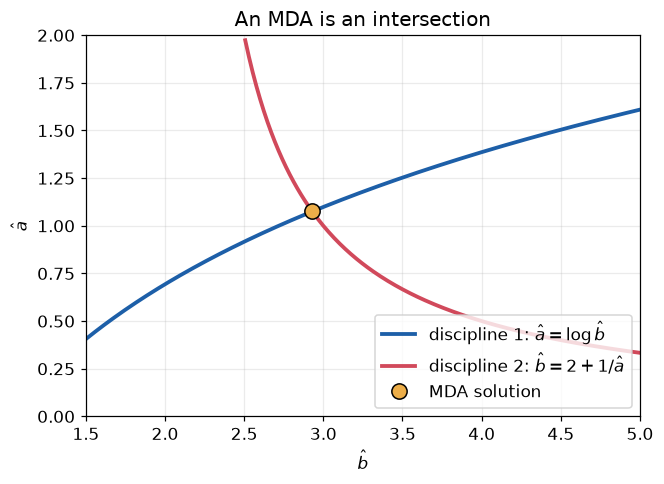

In [4]:
bb = np.linspace(1.5, 5.0, 300)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(bb, U1(bb), color=COLORS["d1"], lw=2.5, label=r"discipline 1: $\hat a = \log \hat b$")
bb2 = bb[bb > 2.5]
ax.plot(bb2, 1.0 / (bb2 - 2.0), color=COLORS["d2"], lw=2.5, label=r"discipline 2: $\hat b = 2 + 1/\hat a$")
ax.plot(u_star[1], u_star[0], "o", ms=10, color=COLORS["solution"], mec="k", label="MDA solution", zorder=5)
ax.set(xlabel=r"$\hat b$", ylabel=r"$\hat a$", xlim=(1.5, 5), ylim=(0, 2), title="An MDA is an intersection")
ax.legend(loc="lower right")
plt.show()

---
## 3. Nonlinear block Gauss-Seidel: *take turns*

Two engineers pass notes. Discipline 1 runs with the **latest** $\hat b$, then discipline 2 runs
with the **new** $\hat a$:

$$
\hat a^{(k)} = \mathcal{U}_1\big(\hat b^{(k-1)}\big), \qquad \hat b^{(k)} = \mathcal{U}_2\big(\hat a^{(k)}\big),
$$

and we stop when $\|\hat{\mathbf{u}}^{(k)} - \hat{\mathbf{u}}^{(k-1)}\| \le \epsilon$.
The function below also counts **discipline evaluations**, because in practice each one is a
CFD or FEA run and that is what costs time.

In [5]:
def gauss_seidel(a0, b0, x=(1.0, 1.0, 1.0), tol=1e-6, max_iter=200, theta=1.0):
    """Nonlinear block Gauss-Seidel MDA. theta < 1 relaxes each full sweep (Section 7).

    Returns a DataFrame with one row per iteration (k = 0 is the initial guess).
    """
    u, v, w = x
    a, b = a0, b0
    rows = [dict(k=0, a=a, b=b, evals=0)]
    evals = 0
    for k in range(1, max_iter + 1):
        a_old, b_old = a, b
        with np.errstate(divide="raise", invalid="raise"):
            try:
                a_new = U1(b, u, v)
                b_new = U2(a_new, u, w)                 # uses the NEW a
                a = a_new
                b = theta * b_new + (1 - theta) * b_old  # relaxation: keep part of the old b
            except FloatingPointError as err:
                rows.append(dict(k=k, a=np.nan, b=np.nan, evals=evals + 2, note=f"crash: {err}"))
                break
        evals += 2
        rows.append(dict(k=k, a=a, b=b, evals=evals))
        if np.hypot(a - a_old, b - b_old) <= tol or not np.isfinite([a, b]).all():
            break
    hist = pd.DataFrame(rows)
    hist["error"] = np.hypot(hist["a"] - u_star[0], hist["b"] - u_star[1]) if x == (1.0, 1.0, 1.0) else np.nan
    return hist


gs = gauss_seidel(1.0, 4.5)
print(f"Gauss-Seidel from (1, 4.5): {len(gs) - 1} iterations, {gs['evals'].iloc[-1]} discipline evaluations")
gs.head(5)

Gauss-Seidel from (1, 4.5): 13 iterations, 26 discipline evaluations


,k,a,b,evals,error
0,0,1,4.5,0,1.57162
1,1,1.50408,2.66486,2,0.504428
2,2,0.980151,3.02025,4,0.130849
3,3,1.10534,2.9047,6,0.0395708
4,4,1.06633,2.9378,8,0.0115891


These are the numbers on the slide *MDA: Running example (4/5)*. The error shrinks by roughly
the same factor (about $0.3$) at every iteration: **linear convergence**.

The staircase below is the same iteration drawn on the picture from Section 2: go vertically
to curve 1 (discipline 1 gives $\hat a$), then horizontally to curve 2 (discipline 2 gives $\hat b$).

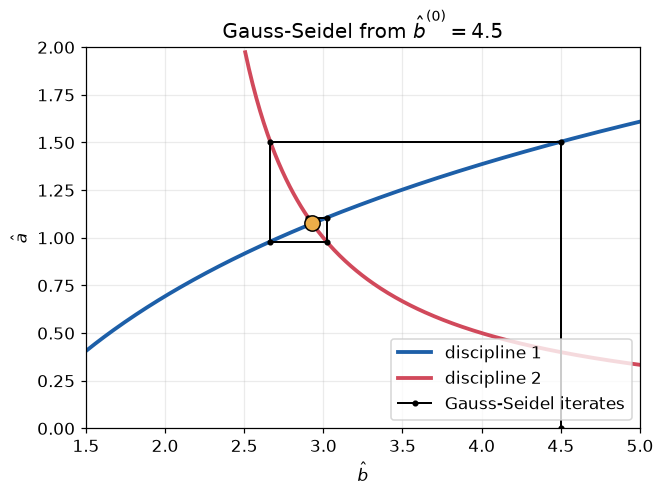

In [6]:
path_b, path_a = [gs["b"].iloc[0]], [0.0]
for (_, prev), (_, row) in zip(gs.iloc[:-1].iterrows(), gs.iloc[1:].iterrows()):
    path_b += [prev["b"], row["b"]]
    path_a += [row["a"], row["a"]]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(bb, U1(bb), color=COLORS["d1"], lw=2.5, label="discipline 1")
ax.plot(bb2, 1.0 / (bb2 - 2.0), color=COLORS["d2"], lw=2.5, label="discipline 2")
ax.plot(path_b[:12], path_a[:12], "k-", lw=1.3, marker=".", label="Gauss-Seidel iterates")
ax.plot(u_star[1], u_star[0], "o", ms=10, color=COLORS["solution"], mec="k", zorder=5)
ax.set(xlabel=r"$\hat b$", ylabel=r"$\hat a$", xlim=(1.5, 5), ylim=(0, 2), title=r"Gauss-Seidel from $\hat b^{(0)} = 4.5$")
ax.legend(loc="lower right")
plt.show()

### A bad start: $\hat a^{(0)} = \hat b^{(0)} = 1$

The slides warn that the start $(1, 1)$ crashes. Discipline 1 returns $\hat a = \log 1 = 0$,
and discipline 2 must then compute $1/0$:

In [7]:
gauss_seidel(1.0, 1.0)

,k,a,b,evals,note,error
0,0,1,1,0,NaN,1.93164
1,1,NaN,NaN,2,crash: divide by zero encountered in scalar di...,NaN


In a real MDA this is a CFD solver that diverges or a mesh that fails. The MDA, and therefore
any optimizer that relies on it, stops here.

---
## 4. Block Jacobi: *work in parallel*

Jacobi runs both disciplines **at the same time** with the other's result from the
**previous** round:

$$
\hat a^{(k)} = \mathcal{U}_1\big(\hat b^{(k-1)}\big), \qquad \hat b^{(k)} = \mathcal{U}_2\big(\hat a^{(k-1)}\big).
$$

In [8]:
def jacobi(a0, b0, x=(1.0, 1.0, 1.0), tol=1e-6, max_iter=400):
    """Nonlinear block Jacobi MDA: both disciplines use the previous iterate (parallelizable)."""
    u, v, w = x
    a, b = a0, b0
    rows = [dict(k=0, a=a, b=b, evals=0)]
    for k in range(1, max_iter + 1):
        a_new, b_new = U1(b, u, v), U2(a, u, w)        # independent: could run on two machines
        step = np.hypot(a_new - a, b_new - b)
        a, b = a_new, b_new
        rows.append(dict(k=k, a=a, b=b, evals=2 * k))
        if step <= tol:
            break
    hist = pd.DataFrame(rows)
    hist["error"] = np.hypot(hist["a"] - u_star[0], hist["b"] - u_star[1])
    return hist


jac = jacobi(1.0, 4.5)
print(f"Jacobi from (1, 4.5): {len(jac) - 1} iterations, {jac['evals'].iloc[-1]} discipline evaluations")
jac.head(5)

Jacobi from (1, 4.5): 24 iterations, 48 discipline evaluations


,k,a,b,evals,error
0,0,1,4.5,0,1.57162
1,1,1.50408,3,2,0.434659
2,2,1.09861,2.66486,4,0.266362
3,3,0.980151,2.91024,6,0.0969836
4,4,1.06824,3.02025,8,0.0903311


Jacobi needs about **twice** as many iterations (24 vs. 13), because each discipline uses
information that is one round old. But both evaluations in a round are independent: with two
computers, a Jacobi round costs one discipline run of wall-clock time, a Gauss-Seidel
iteration costs two. Which is faster depends on your hardware.

---
## 5. Why it converges: the contraction factor

Substitute discipline 1 into discipline 2: one Gauss-Seidel sweep is the scalar map
$\hat b^{(k)} = G\big(\hat b^{(k-1)}\big) = \mathcal{U}_2\big(\mathcal{U}_1(\hat b^{(k-1)})\big)$.
Near the solution the error is multiplied by

$$
|G'(\hat b^*)| = \left|\mathcal{U}_2'(\hat a^*)\,\mathcal{U}_1'(\hat b^*)\right| = \frac{1}{(\hat a^*)^2}\cdot\frac{1}{\hat b^*}.
$$

If this **contraction factor** is below 1, the iteration converges linearly at that rate; if
it is above 1, the iteration is pushed away from the solution. Its sign also matters:
$G' < 0$ means the iterates **alternate** around the solution (the staircase spirals in).

In [9]:
def contraction_factor(x=(1.0, 1.0, 1.0)):
    a, b = mda_reference(x)
    dU1_db = 1.0 / b              # derivative of log(b)
    dU2_da = -1.0 / a ** 2        # derivative of 1/a
    return dU2_da * dU1_db


rho = contraction_factor()
print(f"G'(b*) = {rho:.4f}   ->  |G'| = {abs(rho):.4f}  (< 1: converges, sign < 0: alternates)")
print(f"Observed error ratios, Gauss-Seidel: {(gs['error'].iloc[2:7].values / gs['error'].iloc[1:6].values).round(3)}")
print(f"Predicted Jacobi rate per round sqrt(|G'|) = {np.sqrt(abs(rho)):.3f}")

G'(b*) = -0.2953   ->  |G'| = 0.2953  (< 1: converges, sign < 0: alternates)
Observed error ratios, Gauss-Seidel: [0.259 0.302 0.293 0.296 0.295]
Predicted Jacobi rate per round sqrt(|G'|) = 0.543


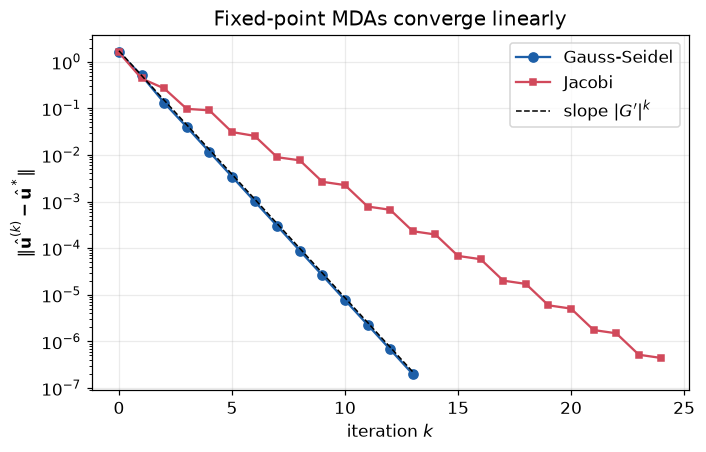

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.semilogy(gs["k"], gs["error"], "o-", color=COLORS["gs"], label="Gauss-Seidel")
ax.semilogy(jac["k"], jac["error"], "s-", color=COLORS["jacobi"], ms=4, label="Jacobi")
k = np.arange(0, 14)
ax.semilogy(k, gs["error"].iloc[1] * abs(rho) ** (k - 1), "k--", lw=1, label=r"slope $|G'|^k$")
ax.set(xlabel="iteration $k$", ylabel=r"$\|\hat{\mathbf{u}}^{(k)} - \hat{\mathbf{u}}^*\|$", title="Fixed-point MDAs converge linearly")
ax.legend()
plt.show()

---
## 6. Reduced-space hierarchical Newton

Instead of passing notes, treat the MDA as **one** system $\hat{\mathbf{r}}(\hat{\mathbf{u}}) = \mathbf{0}$
and apply Newton's method. Each iteration evaluates all disciplines (in parallel), builds the
Jacobian of the residual and solves a linear system:

$$
\frac{\partial \hat{\mathbf{r}}}{\partial \hat{\mathbf{u}}}\,\Delta\hat{\mathbf{u}} = -\hat{\mathbf{r}},
\qquad
\frac{\partial \hat{\mathbf{r}}}{\partial \hat{\mathbf{u}}} = I - \frac{\partial \mathbf{U}}{\partial \hat{\mathbf{u}}}
= \begin{bmatrix} 1 & -1/\hat b \\ 1/\hat a^2 & 1 \end{bmatrix}.
$$

The function supports two ways of getting the discipline Jacobian: **analytic** (the
discipline provides derivatives) and **finite differences** (one extra run of each discipline
per coupling variable). The second is what you do with a commercial code that gives no
derivatives.

In [11]:
def newton_mda(a0, b0, x=(1.0, 1.0, 1.0), tol=1e-10, max_iter=50, jacobian="analytic", h=1e-7):
    u, v, w = x
    uh = np.array([a0, b0], dtype=float)
    rows = [dict(k=0, a=uh[0], b=uh[1], evals=0)]
    evals = 0
    for k in range(1, max_iter + 1):
        r = residual(uh, x)
        evals += 2                                  # U1 and U2 evaluated once each
        if np.linalg.norm(r) <= tol:
            break
        if jacobian == "analytic":
            J = np.array([[1.0, -1.0 / uh[1]], [1.0 / uh[0] ** 2, 1.0]])
        else:                                       # forward differences: perturb each coupling variable
            J = np.empty((2, 2))
            for j in range(2):
                e = np.zeros(2)
                e[j] = h * max(1.0, abs(uh[j]))
                J[:, j] = (residual(uh + e, x) - r) / e[j]
            evals += 2                              # each column needs only the discipline that reads it
        uh = uh + np.linalg.solve(J, -r)
        rows.append(dict(k=k, a=uh[0], b=uh[1], evals=evals))
    hist = pd.DataFrame(rows)
    hist["error"] = np.hypot(hist["a"] - u_star[0], hist["b"] - u_star[1])
    return hist


nt = newton_mda(1.0, 1.0)
nt

,k,a,b,evals,error
0,0,1,1,0,1.93164
1,1,1.5,2.5,2,0.604669
2,2,1.061,2.86178,4,0.0698312
3,3,1.07523,2.92986,6,0.00035867
4,4,1.07506,2.93018,8,2.20979e-08
5,5,1.07506,2.93018,10,4.96507e-16


**Check the slide by hand.** At $\hat{\mathbf{u}}^{(0)} = [1, 1]$: $\hat{\mathbf{r}} = [1, -2]$,
the Jacobian is $\begin{bmatrix}1 & -1\\ 1 & 1\end{bmatrix}$, so $\Delta\hat{\mathbf{u}} = [0.5, 1.5]$
and $\hat{\mathbf{u}}^{(1)} = [1.5, 2.5]$: the first row of the table. Newton starts from the
point that **crashed** Gauss-Seidel without trouble, because it updates $\hat a$ and $\hat b$
simultaneously and never evaluates discipline 2 at $\hat a = 0$.

The error column shows **quadratic convergence**: the number of correct digits roughly doubles
every iteration ($10^{-1} \to 10^{-2} \to 10^{-4} \to 10^{-8}$).

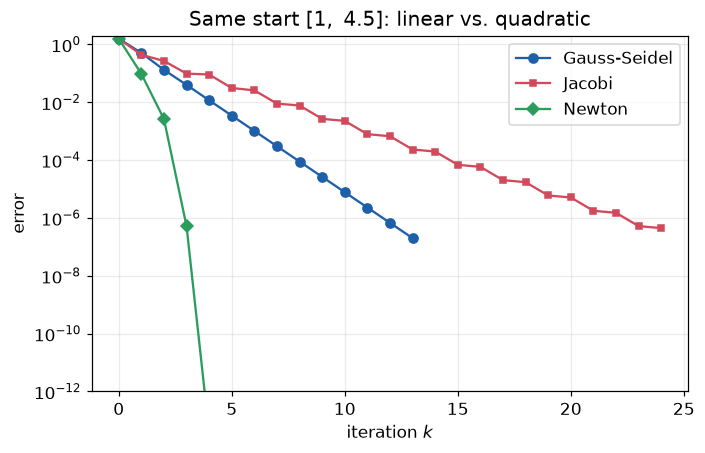

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.2))
nt45 = newton_mda(1.0, 4.5)
ax.semilogy(gs["k"], gs["error"], "o-", color=COLORS["gs"], label="Gauss-Seidel")
ax.semilogy(jac["k"], jac["error"], "s-", color=COLORS["jacobi"], ms=4, label="Jacobi")
ax.semilogy(nt45["k"], np.maximum(nt45["error"], 1e-16), "D-", color=COLORS["newton"], label="Newton")
ax.set(xlabel="iteration $k$", ylabel="error", ylim=(1e-12, 2), title=r"Same start $[1,\ 4.5]$: linear vs. quadratic")
ax.legend()
plt.show()

---
## 7. When fixed-point iteration fails, and how to fix it

The contraction factor depends on the **design point** $\mathbf{x}$, because the disciplines'
sensitivities do. The cell below computes it as $v$ decreases (with $u = w = 1$).

In [13]:
rows = []
for v in [1.0, 0.8, 0.6, 0.5, 0.4, 0.3]:
    a, b = mda_reference((1.0, v, 1.0))
    rows.append(dict(v=v, a_star=a, b_star=b, contraction=abs(contraction_factor((1.0, v, 1.0)))))
pd.DataFrame(rows)

,v,a_star,b_star,contraction
0,1,1.07506,2.93018,0.295283
1,0.8,0.908492,3.10072,0.390746
2,0.6,0.713439,3.40166,0.577558
3,0.5,0.603498,3.65701,0.750798
4,0.4,0.485171,4.06113,1.04608
5,0.3,0.360001,4.77777,1.61498


At $v = 0.3$ the factor is $1.61 > 1$. The disciplines and the solver are unchanged, yet
Gauss-Seidel now **diverges**, even when it starts very close to the solution:

In [14]:
x_hard = (1.0, 0.3, 1.0)
ref_hard = mda_reference(x_hard)
gs_hard = gauss_seidel(ref_hard[0] + 0.01, ref_hard[1] + 0.01, x=x_hard, max_iter=12)
gs_hard["distance to solution"] = np.hypot(gs_hard["a"] - ref_hard[0], gs_hard["b"] - ref_hard[1])
gs_hard[["k", "a", "b", "distance to solution"] + (["note"] if "note" in gs_hard else [])]

,k,a,b,distance to solution
0,0,0.370001,4.78777,0.0141421
1,1,0.362092,4.76173,0.0161755
2,2,0.356638,4.80396,0.0264072
3,3,0.365468,4.73622,0.0419114
4,4,0.351266,4.84685,0.0696275
5,5,0.374356,4.67126,0.107476
6,6,0.337455,4.96335,0.186949
7,7,0.398109,4.51187,0.268612
8,8,0.30274,5.30317,0.528507
9,9,0.464331,4.15364,0.632794


This is why **MDF is fragile**: an optimizer that moves the design can walk into a region
where the MDA no longer converges. Two fixes:

1. **Relaxation.** Take only a fraction $\theta$ of each update. A Gauss-Seidel sweep only
   carries $\hat b$ to the next iteration, so we relax $\hat b$:
   $\hat b^{(k)} \gets \theta\,\mathcal{U}_2(\hat a^{(k)}) + (1-\theta)\,\hat b^{(k-1)}$.
   Near the solution the error is multiplied by approximately $1 - \theta + \theta G'$. With
   $G' = -1.61$, any $\theta < 2/2.61 \approx 0.77$ converges, and $\theta = 1/2.61 \approx 0.38$
   is optimal.
2. **Newton**, which does not rely on a contraction at all.

In [15]:
results = {}
for theta in [1.0, 0.7, 0.38]:
    h = gauss_seidel(ref_hard[0] + 0.01, ref_hard[1] + 0.01, x=x_hard, theta=theta, max_iter=200)
    ok = np.isfinite(h["a"].iloc[-1]) and np.hypot(h["a"].iloc[-1] - ref_hard[0], h["b"].iloc[-1] - ref_hard[1]) < 1e-5
    results[f"Gauss-Seidel, theta = {theta}"] = (len(h) - 1, h["evals"].iloc[-1], "converged" if ok else "FAILED")
h = newton_mda(1.0, 4.5, x=x_hard)
results["Newton from (1, 4.5)"] = (len(h) - 1, h["evals"].iloc[-1],
                                   "converged" if np.hypot(h["a"].iloc[-1] - ref_hard[0], h["b"].iloc[-1] - ref_hard[1]) < 1e-8 else "FAILED")
pd.DataFrame(results, index=["iterations", "discipline evaluations", "status"]).T

,iterations,discipline evaluations,status
"Gauss-Seidel, theta = 1.0",15,30,FAILED
"Gauss-Seidel, theta = 0.7",54,108,converged
"Gauss-Seidel, theta = 0.38",4,8,converged
"Newton from (1, 4.5)",6,12,converged


---
## 8. The race, measured in discipline evaluations

Iterations are not the whole story. Newton with finite-difference Jacobians pays for extra
discipline runs; Jacobi can run its two evaluations in parallel. The table compares the
solvers from the same start at $u = v = w = 1$, to the same accuracy.

In [16]:
race = {
    "Block Jacobi": jacobi(1.0, 4.5),
    "Block Gauss-Seidel": gauss_seidel(1.0, 4.5),
    "Newton (analytic Jacobian)": newton_mda(1.0, 4.5),
    "Newton (finite differences)": newton_mda(1.0, 4.5, jacobian="fd"),
}
summary = pd.DataFrame({
    name: {"iterations": len(h) - 1,
           "discipline evaluations": int(h["evals"].iloc[-1]),
           "wall-clock units (2 machines)": int(h["evals"].iloc[-1] / 2) if "Gauss" not in name else int(h["evals"].iloc[-1]),
           "final error": h["error"].iloc[-1]}
    for name, h in race.items()}).T
summary

,iterations,discipline evaluations,wall-clock units (2 machines),final error
Block Jacobi,24,48,24,4.40407e-07
Block Gauss-Seidel,13,26,26,1.98138e-07
Newton (analytic Jacobian),4,8,4,3.68594e-14
Newton (finite differences),4,16,8,4.80376e-14


*Wall-clock units* count one discipline run as one unit, with two machines available: Jacobi
and Newton evaluate both disciplines simultaneously, Gauss-Seidel cannot. Newton wins here
even with finite differences, but its Jacobian costs grow with the **number of coupling
variables**: with thousands of coupling variables (one per panel and per finite-element node),
a fixed-point method can be cheaper per unit of accuracy.

---
## Exercises

1. **Jacobi with relaxation.** Add a `theta` argument to `jacobi`. What is the best $\theta$ at
   $\mathbf{x} = (1, 0.3, 1)$? (Hint: Jacobi's error multiplier per round has magnitude
   $\sqrt{|G'|}$ and is complex.)
2. **Order matters.** Write a Gauss-Seidel variant that runs discipline 2 first. Does the
   contraction factor change? Does the bad start $(1, 1)$ still crash?
3. **Map the danger zone.** Compute the contraction factor on a grid of $(v, w)$ with $u = 1$
   and plot the contour $|G'| = 1$. Where in the design space would an MDF optimizer using
   Gauss-Seidel get into trouble?

---
## Takeaways

1. An MDA finds coupling variables that all disciplines agree on; geometrically it is the
   **intersection** of the disciplines' response curves.
2. Gauss-Seidel and Jacobi are fixed-point iterations: they converge linearly at the rate
   $|G'|$ (Jacobi at $\sqrt{|G'|}$ per round), and only if $|G'| < 1$.
3. The contraction factor depends on the design. An MDA that converges at the baseline can
   diverge elsewhere; relaxation or Newton fixes it.
4. Newton converges quadratically and survives starts that crash Gauss-Seidel, but needs
   discipline Jacobians, analytic or finite-difference.
5. Compare MDA solvers by **discipline evaluations and wall-clock time**, not iterations.